In [11]:
#Import required libraries

import pandas as pd

In [18]:
#Read the dataset

ds = pd.read_csv("sales_data_sample.csv", encoding="Latin-1")

print(ds.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [13]:
from sklearn.preprocessing import StandardScaler

X = ds[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

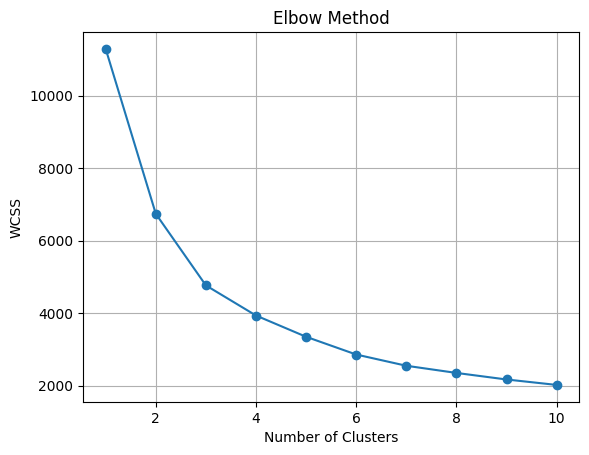

In [14]:
# 3. Determine number of clusters using Elbow Method

from sklearn.cluster import KMeans, AgglomerativeClustering
import matplotlib.pyplot as plt

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()

In [15]:
# 4. Apply K-Means Clustering

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

ds['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

#Extra part
print(ds[['SALES', 'QUANTITYORDERED', 'KMeans_Cluster']].head())

     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30               2
1  2765.90               34               2
2  3884.34               41               1
3  3746.70               45               1
4  5205.27               49               1


In [16]:
# 5. Apply Hierarchical Clustering

hc = AgglomerativeClustering(n_clusters=3)

ds['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

#Extra part
print(ds[['SALES', 'QUANTITYORDERED', 'Hierarchical_Cluster']].head())

     SALES  QUANTITYORDERED  Hierarchical_Cluster
0  2871.00               30                     2
1  2765.90               34                     2
2  3884.34               41                     0
3  3746.70               45                     0
4  5205.27               49                     1


In [17]:
print("K-Means Clusters:")
print(ds['KMeans_Cluster'].value_counts())

print("\nHierarchical Clusters:")
print(ds
['Hierarchical_Cluster'].value_counts())

K-Means Clusters:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64

Hierarchical Clusters:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64
